In [35]:
import pandas as pd
import plotly.express as px
import seaborn as sns

#https://python-visualization.github.io/folium/latest/getting_started.html
#https://python-graph-gallery.com/292-choropleth-map-with-folium/
#https://seaborn.pydata.org/generated/seaborn.heatmap.html
#https://plotly.com/python/choropleth-maps/

In [2]:
# Load us population data to a dataframe.
df_pop = pd.read_csv('us_pop.csv')

In [4]:
# Create a choropleth map. 
fig = px.choropleth(df_pop,  # Input dataframe
                    locations="state",  # which column for locations
                    color="value",  # which column for values
                    color_continuous_scale="Viridis",
                    hover_name="state", # mouse hover info
                    locationmode = 'USA-states',
                    labels={'value':'Population'}) 

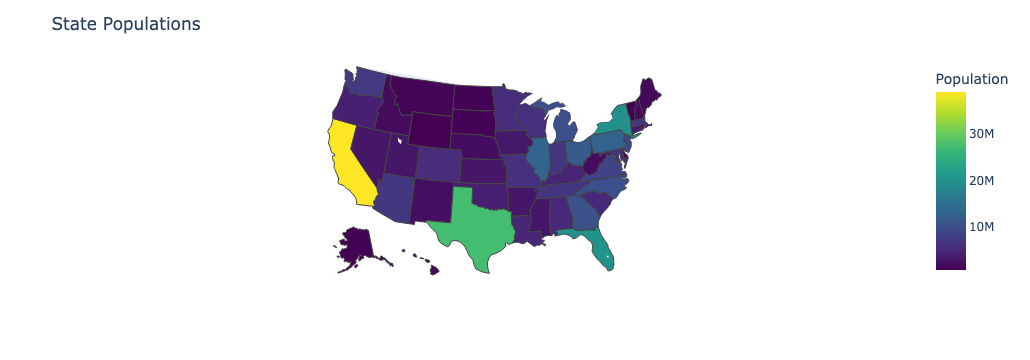

In [9]:
# Show the choropleth map.
fig.update_layout(
    title_text = 'State Populations', #  Title
    geo_scope='usa',  # Plot only the USA instead of globe
)

In [10]:
# Load the us area data in csv to a dataframe.
df_area = pd.read_csv('us_area.csv')

In [11]:
# Create a choropleth map.
fig_2 = px.choropleth(df_area,   
                    locations="state",  
                    color="value",  
                    hover_name="state", 
                    locationmode = 'USA-states', 
                    labels={'value':'Area'}) 

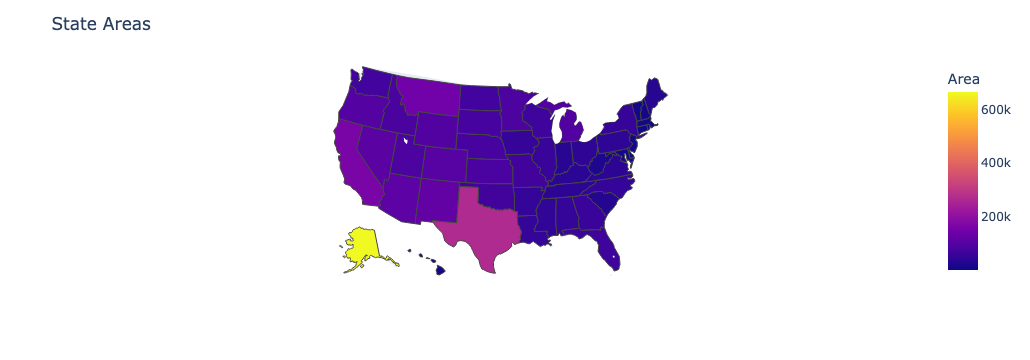

In [12]:
# Show the choropleth map.
fig_2.update_layout(
    title_text = 'State Areas', 
    geo_scope='usa',  
)

In [13]:
# Load the world-wide covid 19 data in csv to a dataframe.
import pandas as pd
df_covid = pd.read_csv("covid_19_world.csv")

In [14]:
len(df_covid)


61900

In [15]:
df_covid.head()

,dateRep,day,month,year,cases,deaths,countriesAndTerritories,popData2019,continentExp
0,12/14/2020,14,12,2020,746,6,Afghanistan,38041757.0,Asia
1,12/13/2020,13,12,2020,298,9,Afghanistan,38041757.0,Asia
2,12/12/2020,12,12,2020,113,11,Afghanistan,38041757.0,Asia
3,12/11/2020,11,12,2020,63,10,Afghanistan,38041757.0,Asia
4,12/10/2020,10,12,2020,202,16,Afghanistan,38041757.0,Asia


In [16]:
# Group cases by country.
df_covid.groupby('countriesAndTerritories')['cases'].count()

countriesAndTerritories
Afghanistan          340
Albania              281
Algeria              345
Andorra              276
Angola               268
                    ... 
Wallis_and_Futuna     59
Western_Sahara       233
Yemen                249
Zambia               271
Zimbabwe             269
Name: cases, Length: 214, dtype: int64

In [17]:
# Sum up the total cases.
df_covid.groupby('countriesAndTerritories')['cases'].sum()

countriesAndTerritories
Afghanistan          49273
Albania              48530
Algeria              92102
Andorra               7338
Angola               16188
                     ...  
Wallis_and_Futuna        3
Western_Sahara         766
Yemen                 2083
Zambia               18274
Zimbabwe             11246
Name: cases, Length: 214, dtype: int64

In [18]:
# Create a new dataframe to save the case results.
s = df_covid.groupby('countriesAndTerritories')['cases'].sum()
df_cases = pd.DataFrame({'Country': s.index, 'cases':s.values})
df_cases.head()

,Country,cases
0,Afghanistan,49273
1,Albania,48530
2,Algeria,92102
3,Andorra,7338
4,Angola,16188


In [19]:
# Find out the iso names of all countries.
iso_names = pd.read_csv("country_iso.csv", encoding='latin-1')
country_names = list(iso_names['Country'])
country_name_clean = []
for name in country_names:
    country_name_clean.append(name.strip())
country_iso = list(iso_names['iso_3'])

In [ ]:
# Match to the countries in the covid data. 
country_iso_matched = []
country_names_matched = []
country_cases_matched = []
for i in range(len(df_cases)):
    #print(df_cases.iloc[i,0])
    name = df_cases.iloc[i,0]
    for j in range(len(country_name_clean)):
        if name == country_name_clean[j]:
            print(name)
            print(country_iso[j])
            country_names_matched.append(name)
            country_iso_matched.append(country_iso[j].strip())
            country_cases_matched.append(df_cases.iloc[i, 1])
            print("-----------------------")

In [21]:
# Create a new dataframe with iso country codes.
dict_new = {'country': country_names_matched, 'iso':country_iso_matched, "cases": country_cases_matched }
df_final = pd.DataFrame(dict_new)

In [22]:
df_final

,country,iso,cases
0,Afghanistan,AFG,49273
1,Albania,ALB,48530
2,Algeria,DZA,92102
3,Andorra,AND,7338
4,Angola,AGO,16188
...,...,...,...
138,Uzbekistan,UZB,75094
139,Vanuatu,VUT,1
140,Yemen,YEM,2083
141,Zambia,ZMB,18274


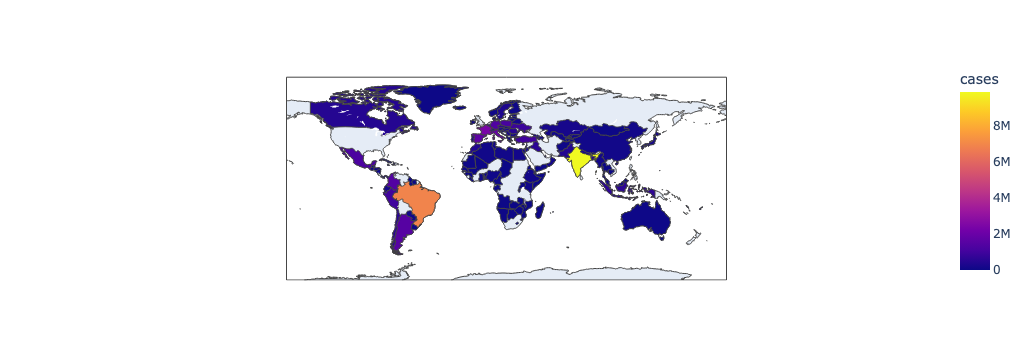

In [23]:
# Plot and show the choropleth map.
import plotly.express as px

fig = px.choropleth(df_final, locations="iso",
                    color="cases", # lifeExp is a column of gapminder
                    hover_name="country", # column to add to hover information
                    color_continuous_scale=px.colors.sequential.Plasma)
fig.show()

In [24]:
# Folium is another visualization package that 
# has strong spatial visualization support. 
import folium

In [25]:
# Center the map location. This is where Indianapolis is. 
indy = folium.Map(location=[39.79, -86.148], zoom_start=7)

In [26]:
indy

In [28]:
# Create a choropleth map using folium. 
import folium
indy = folium.Map(location=[39.79, -86.148], zoom_start=7)

state_geo = "indiana_counties.json"
state_unemployment = "indiana.csv"
state_data = pd.read_csv(state_unemployment)
#
folium.Choropleth(
    geo_data=state_geo,
    name="choropleth",
    data=state_data,
    columns=["County", "Population"],
    key_on="feature.id",
    fill_color="YlGn",
    fill_opacity=0.7,
    line_opacity=.5
).add_to(indy)

folium.LayerControl().add_to(indy)
indy

In [30]:
# Create a US cholopleth map using folium. 
import folium
usa = folium.Map(location=[40, -95], zoom_start=4)
state_geo = "usa_states.json"
state_unemployment = "us_unemployment_oct2012.csv"
state_data = pd.read_csv(state_unemployment)
folium.Choropleth(
    geo_data=state_geo,
    name="choropleth",
    data=state_data,
    columns=["State", "Unemployment"],
    key_on="feature.id",
    fill_color="YlGn",
    fill_opacity=0.7,
    line_opacity=.1,
    legend_name="Unemployment Rate (%)",
).add_to(usa)

folium.LayerControl().add_to(usa)

usa

In [31]:
# Load the california housing data.
df = pd.read_csv("housing.csv")

In [32]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [33]:
df2 = df.copy().drop_duplicates(['longitude', 'latitude'])[0:100]

In [34]:
# Show the housing data over a local map.
housing_map = folium.Map( location=[ df2.latitude.mean(), df2.longitude.mean() ], zoom_start=12)
for coord in df2[['latitude','longitude']].values:
    folium.CircleMarker(location=[coord[0],coord[1]], radius=3,color='red').add_to(housing_map)
housing_map

In [36]:
# Create a two-dimensiona list of integers.
l = [[20, 10, 10], [25, 10, 15], [30, 20, 10], [35, 25, 20]]

<Axes: >

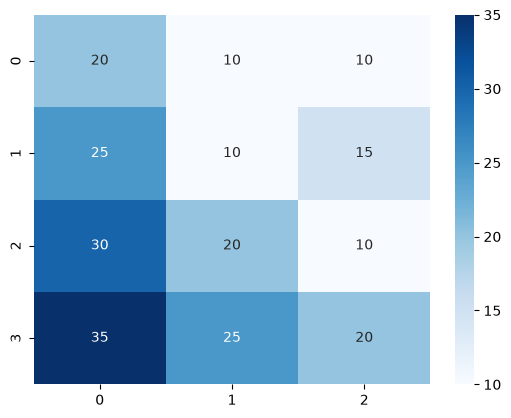

In [38]:
# Draw a heatmap with only one color.
sns.heatmap(l, cmap = 'Blues', annot=True)

<Axes: >

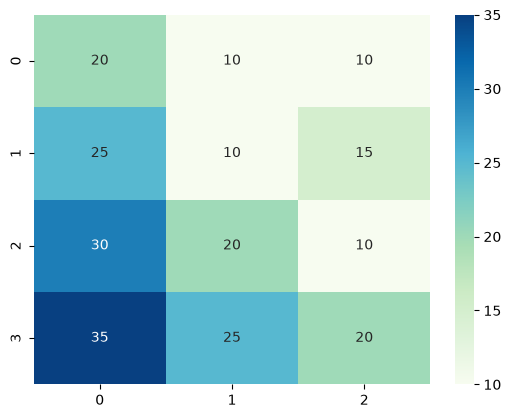

In [39]:
# Draw a heatmap with two colors.
sns.heatmap(l, cmap = 'GnBu', annot=True)

<Axes: >

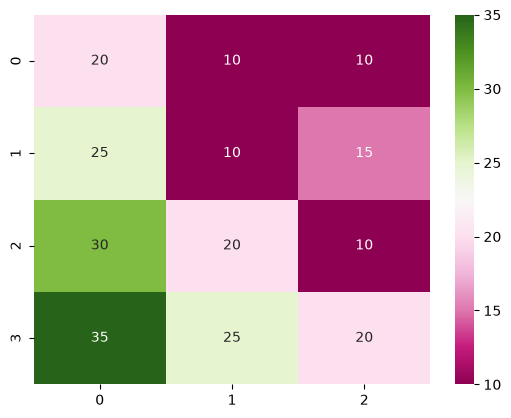

In [40]:
# Draw a heatmap with three colors.
sns.heatmap(l, cmap = 'PiYG', annot=True)

<Axes: >

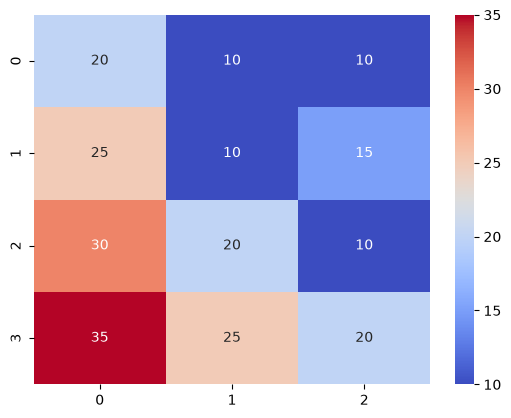

In [41]:
# Draw a heatmap with predefined color palette. 
sns.heatmap(l, cmap = 'coolwarm', annot=True)

<Axes: >

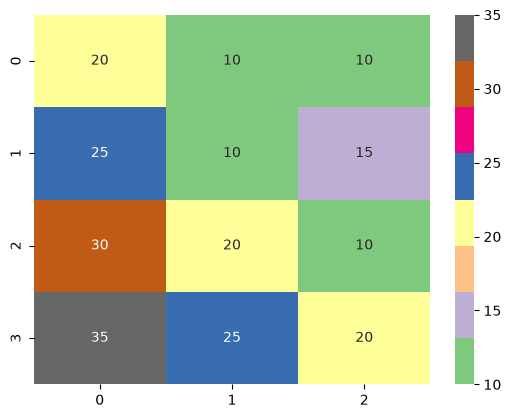

In [42]:
# Qualitative color map
sns.heatmap(l, cmap = 'Accent', annot=True)

In [43]:
# Load a sample data in seaborn into a dataframe.
glue = sns.load_dataset("glue").pivot(index="Model", columns="Task", values="Score")

In [44]:
glue

Task,CoLA,MNLI,MRPC,QNLI,QQP,RTE,SST-2,STS-B
Model,,,,,,,,
BERT,60.5,86.7,89.3,92.7,72.1,70.1,94.9,87.6
BiLSTM,11.6,65.6,81.8,74.6,62.5,57.4,82.8,70.3
BiLSTM+Attn,18.6,67.6,83.9,74.3,60.1,58.4,83.0,72.8
BiLSTM+CoVe,18.5,65.4,78.7,70.8,60.6,52.7,81.9,64.4
BiLSTM+ELMo,32.1,67.2,84.7,75.5,61.1,57.4,89.3,70.3
ERNIE,75.5,92.3,93.9,97.3,75.2,92.6,97.8,93.0
RoBERTa,67.8,90.8,92.3,95.4,74.3,88.2,96.7,92.2
T5,71.6,92.2,92.8,96.9,75.1,92.8,97.5,93.1


<Axes: xlabel='Task', ylabel='Model'>

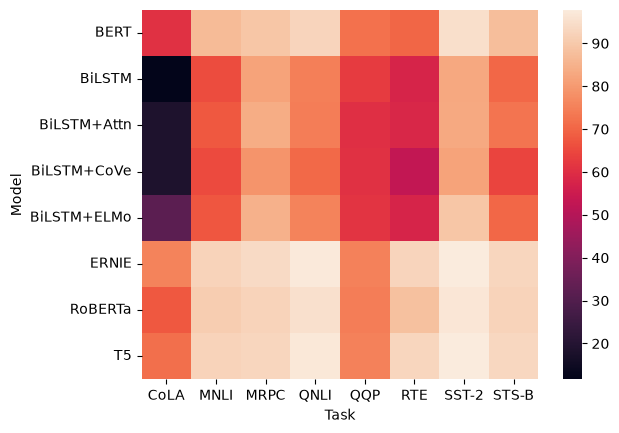

In [45]:
# Draw a heatmap from a dataframe.
# Use the index labels and columns as X and Y labels on the heatmap.
sns.heatmap(glue)

<Axes: xlabel='Task', ylabel='Model'>

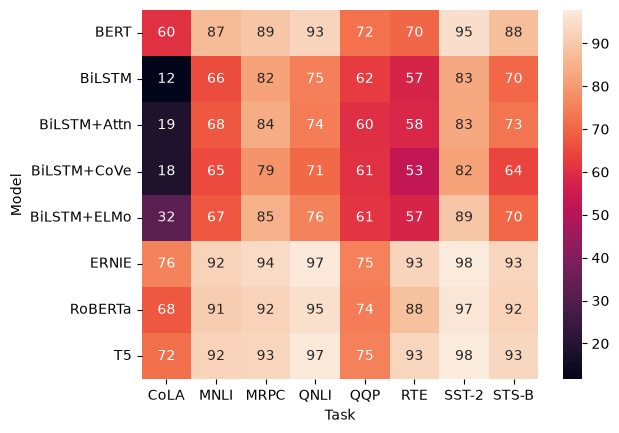

In [46]:
# Display the value on each square. 
sns.heatmap(glue, annot=True)

<Axes: xlabel='Task', ylabel='Model'>

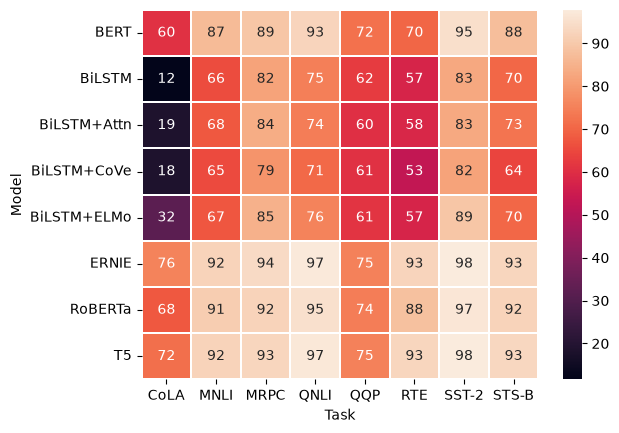

In [47]:
# Improve the visualization by introducing grid lines. 
sns.heatmap(glue, annot=True, linewidth=0.3)

<Axes: xlabel='Task', ylabel='Model'>

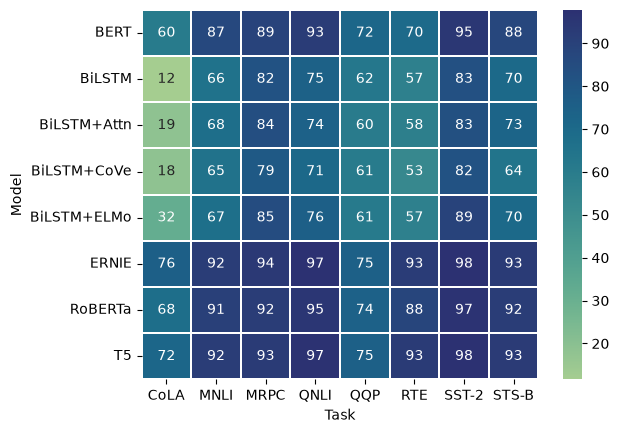

In [48]:
# Using a different color map for heatmap. 
sns.heatmap(glue, annot=True, linewidth=0.3, cmap='crest')

In [49]:
#Homework

In [50]:
alcohol = pd.read_csv("alcohol.csv")

In [51]:
country_iso = pd.read_csv("country_iso.csv")

In [69]:
#Largest Alcohol consumption
alcohol.max()

location    Zimbabwe
alcohol         17.5
dtype: object

In [67]:
#Smallest Alcohol consumption
alcohol['alcohol'].min()

np.float64(0.1)

In [63]:
alcohol

,location,alcohol
0,Belarus,17.5
1,Moldova,16.8
2,Lithuania,15.4
3,Russia,15.1
4,Romania,14.4
...,...,...
185,Bangladesh,0.2
186,Kuwait,0.1
187,Libya,0.1
188,Mauritania,0.1


In [66]:
#Average Alcohol consumption for alcohol column
alcohol['alcohol'].mean()

np.float64(6.212631578947369)

In [73]:
# 2. Extract the first letter of each location
alcohol['first_letter'] = alcohol['location'].str[0].str.upper()

# 3. Group by the first letter and calculate total/average consumption
# (Using .sum() here, change to .mean() if you want the average per group)
grouped = alcohol.groupby('first_letter')['alcohol'].sum().reset_index()

# 4. Find and display the group with the highest consumption
highest_consumption_group = grouped.loc[grouped['alcohol'].idxmax()]

print("Grouped Consumption:")
print(grouped)
print("\nGroup with the most alcohol consumption:")
print(highest_consumption_group)

Grouped Consumption:
   first_letter  alcohol
0             A     69.4
1             B    115.0
2             C    117.2
3             D     26.7
4             E     33.0
5             F     27.5
6             G     78.0
7             H     23.7
8             I     40.9
9             J     12.8
10            K     22.0
11            L     60.6
12            M     71.4
13            N     72.1
14            O      0.9
15            P     72.1
16            Q      1.5
17            R     42.9
18            S    166.7
19            T     38.1
20            U     61.0
21            V     16.9
22            Y      0.3
23            Z      9.7

Group with the most alcohol consumption:
first_letter        S
alcohol         166.7
Name: 18, dtype: object


In [74]:
#Countries with most alcohol consumption
top_locations = alcohol.sort_values(by="alcohol", ascending=False).head(10)

In [75]:
print(top_locations)

         location  alcohol first_letter
0         Belarus     17.5            B
1         Moldova     16.8            M
2       Lithuania     15.4            L
3          Russia     15.1            R
4         Romania     14.4            R
5         Ukraine     13.9            U
6         Andorra     13.8            A
7         Hungary     13.3            H
8  Czech Republic     13.0            C
9        Slovakia     13.0            S


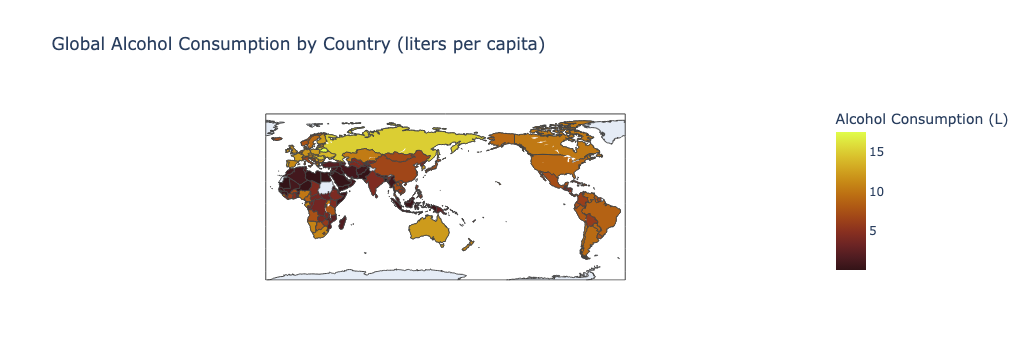

In [88]:
import pandas as pd
import plotly.express as px

# 1. Load the datasets
alcohol_df = pd.read_csv('alcohol.csv')
country_iso_df = pd.read_csv('country_iso.csv')

# 2. Clean whitespace from columns for accurate merging
alcohol_df['location'] = alcohol_df['location'].str.strip()
country_iso_df['Country'] = country_iso_df['Country'].str.strip()
country_iso_df['iso_3'] = country_iso_df['iso_3'].str.strip()

# 3. Merge the datasets on country names
merged_df = pd.merge(
    alcohol_df, 
    country_iso_df, 
    left_on='location', 
    right_on='Country', 
    how='inner'
)

# 4. Create the Choropleth map using Plotly
fig = px.choropleth(
    merged_df,
    locations='iso_3',
    color='alcohol',
    hover_name='location',
    color_continuous_scale='solar',
    title='Global Alcohol Consumption by Country (liters per capita)',
    labels={'alcohol': 'Alcohol Consumption (L)'}
)

# 5. Display the map in JupyterLab
fig.show()


In [85]:
print("Alcohol CSV columns:", pd.read_csv("alcohol.csv").columns.tolist())
print("ISO CSV columns:", pd.read_csv("country_iso.csv").columns.tolist())


Alcohol CSV columns: ['location', 'alcohol']
ISO CSV columns: ['Country', 'iso_3']
